# Exercício 3 — Padronização e Escalonamento
**Disciplina:** Ciência de Dados · **Etapa CRISP-DM:** Preparação dos Dados
**Dataset:** Adult Census Income (UCI) — `adult.data` + `adult.names`

**Objetivo:** encontrar e corrigir as inconsistências escondidas em um dataset que "parece limpo" e, depois, escalonar as colunas numéricas para uso em modelos.

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)

In [2]:
# NOMES DAS COLUNAS (consulte a documentação do dataset)
# Fonte: adult.names (UCI) — o arquivo adult.data não tem cabeçalho.
colunas = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
           'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
           'hours-per-week', 'native-country', 'income']

In [3]:
# CARREGAMENTO DOS DADOS
# Não uso skipinitialspace=True de propósito: quero ENXERGAR o problema dos espaços antes de corrigi-lo.
df = pd.read_csv('adult.data', header=None, names=colunas)
print('Dimensões:', df.shape)
df.head()

Dimensões: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
print('Total de valores ausentes segundo o pandas (isna):', df.isna().sum().sum())
print('Linhas duplicadas exatas:', df.duplicated().sum())
df.dtypes.astype(str).to_frame('tipo')

Total de valores ausentes segundo o pandas (isna): 0
Linhas duplicadas exatas: 24


,tipo
age,int64
workclass,str
fnlwgt,int64
education,str
education-num,int64
marital-status,str
occupation,str
relationship,str
race,str
sex,str


O pandas informa **0 valores ausentes**. A base parece limpa, e é aí que mora o engano (ver reflexão 1). Vamos inspecionar os textos.

## Inspeção das colunas categóricas

In [5]:
# INSPEÇÃO DAS COLUNAS CATEGÓRICAS
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print('Colunas categóricas:', cat_cols)
print()

# (a) espaços extras, (b) variações de capitalização/grafia, (c) marcadores de desconhecido
inspecao = pd.DataFrame({
    'valores_distintos': [df[c].nunique() for c in cat_cols],
    'com_espaço_nas_pontas': [(df[c] != df[c].str.strip()).sum() for c in cat_cols],
    'distintos_após_strip': [df[c].str.strip().nunique() for c in cat_cols],
    'distintos_após_strip+lower': [df[c].str.strip().str.lower().nunique() for c in cat_cols],
    "marcador '?'": [(df[c].str.strip() == '?').sum() for c in cat_cols],
}, index=cat_cols)
inspecao

Colunas categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']



,valores_distintos,com_espaço_nas_pontas,distintos_após_strip,distintos_após_strip+lower,marcador '?'
workclass,9,32561,9,9,1836
education,16,32561,16,16,0
marital-status,7,32561,7,7,0
occupation,15,32561,15,15,1843
relationship,6,32561,6,6,0
race,5,32561,5,5,0
sex,2,32561,2,2,0
native-country,42,32561,42,42,583
income,2,32561,2,2,0


In [6]:
# Como esses valores se parecem de verdade? repr() mostra os espaços invisíveis
for c in ['workclass', 'income', 'native-country']:
    print(c, '->', [repr(v) for v in df[c].unique()[:8]])

workclass -> ["' State-gov'", "' Self-emp-not-inc'", "' Private'", "' Federal-gov'", "' Local-gov'", "' ?'", "' Self-emp-inc'", "' Without-pay'"]
income -> ["' <=50K'", "' >50K'"]
native-country -> ["' United-States'", "' Cuba'", "' Jamaica'", "' India'", "' ?'", "' Mexico'", "' South'", "' Puerto-Rico'"]


**O que a inspeção mostra:**
- **(a) Espaços extras:** *todas* as colunas de texto têm um espaço no **início** de cada valor (`' Private'`, `' <=50K'`...). Para o Python, `' Private'` e `'Private'` são textos diferentes. Se alguém filtrar `df[df.workclass == 'Private']`, obtém **zero linhas**.
- **(b) Capitalização/grafia:** nesta base, depois do `strip`, o número de categorias **não muda** com `lower()`. Ou seja, **não existem** variações de maiúscula/minúscula nem de grafia para a mesma categoria. Verifiquei, e é bom registrar que o problema **não existe aqui**, em vez de assumir que existe.
- **(c) Marcador de desconhecido:** o texto `?` aparece em `workclass`, `occupation` e `native-country`. O pandas o trata como uma categoria comum, por isso `isna()` retorna zero.

## Padronização dos textos (antes x depois)

In [7]:
# PADRONIZAÇÃO DOS TEXTOS (ANTES x DEPOIS)
df_pad = df.copy()
for c in cat_cols:
    df_pad[c] = df_pad[c].str.strip().str.replace(r'\s+', ' ', regex=True)   # tira pontas e espaços duplicados no meio

antes_depois = pd.DataFrame({
    'categorias_antes': [df[c].nunique() for c in cat_cols],
    'categorias_depois': [df_pad[c].nunique() for c in cat_cols],
    'valores_com_espaço_antes': [(df[c] != df[c].str.strip()).sum() for c in cat_cols],
    'valores_com_espaço_depois': [(df_pad[c] != df_pad[c].str.strip()).sum() for c in cat_cols],
}, index=cat_cols)
antes_depois

,categorias_antes,categorias_depois,valores_com_espaço_antes,valores_com_espaço_depois
workclass,9,9,32561,0
education,16,16,32561,0
marital-status,7,7,32561,0
occupation,15,15,32561,0
relationship,6,6,32561,0
race,5,5,32561,0
sex,2,2,32561,0
native-country,42,42,32561,0
income,2,2,32561,0


In [8]:
# Prova de que a correção funciona: o mesmo filtro, antes e depois
print("df['workclass'] == 'Private'      ->", (df['workclass'] == 'Private').sum(), 'linhas (antes)')
print("df_pad['workclass'] == 'Private'  ->", (df_pad['workclass'] == 'Private').sum(), 'linhas (depois)')
print(f"Renda >50K: {(df_pad['income'] == '>50K').mean()*100:.1f}% da base")

df['workclass'] == 'Private'      -> 0 linhas (antes)
df_pad['workclass'] == 'Private'  -> 22696 linhas (depois)
Renda >50K: 24.1% da base


**Observação:** o número de categorias distintas **não muda** (ex.: `workclass` tem 9 antes e 9 depois), porque o espaço era aplicado de forma uniforme em todos os valores. O ganho está na **igualdade de texto**: o filtro que antes retornava 0 linhas agora retorna as corretas. Por isso a métrica "número de categorias" sozinha não revela o problema e é preciso medir também "valores com espaço nas pontas".

## Conversão dos marcadores de ausência

In [9]:
# CONVERSÃO DOS MARCADORES DE AUSÊNCIA
df_nan = df_pad.replace('?', np.nan)

aus = pd.DataFrame({
    'ausentes_antes': df_pad.isna().sum(),
    'ausentes_depois': df_nan.isna().sum(),
})
aus['apareceram'] = aus['ausentes_depois'] - aus['ausentes_antes']
aus['pct_da_coluna'] = aus['apareceram'] / len(df_nan) * 100
aus = aus[aus['apareceram'] > 0]
print(aus)
print(f"\nTotal de células 'escondidas': {aus['apareceram'].sum():,}")
n_lin = df_nan.isna().any(axis=1).sum()
print(f'Linhas com pelo menos um ausente: {n_lin:,} ({n_lin/len(df_nan)*100:.1f}%)')
juntas = (df_nan['workclass'].isna() & df_nan['occupation'].isna()).sum()
print(f"Linhas em que workclass E occupation faltam juntas: {juntas:,} (de {df_nan['workclass'].isna().sum():,} ausentes em workclass)")

                ausentes_antes  ausentes_depois  apareceram  pct_da_coluna
workclass                    0             1836        1836          5.639
occupation                   0             1843        1843          5.660
native-country               0              583         583          1.790

Total de células 'escondidas': 4,262
Linhas com pelo menos um ausente: 2,399 (7.4%)
Linhas em que workclass E occupation faltam juntas: 1,836 (de 1,836 ausentes em workclass)


**Resultado:** apareceram **1.836** ausentes em `workclass`, **1.843** em `occupation` e **583** em `native-country`, ou seja, 4.262 valores que o `isna()` não enxergava. Ao todo, 2.399 linhas (7,4%) têm ao menos um ausente, e `workclass` e `occupation` faltam quase sempre **nas mesmas linhas** (ver contagem acima), o que sugere registros incompletos na origem. Ignorar isso levaria um modelo a tratar `?` como uma profissão qualquer.

## Escalonamento das colunas numéricas
Colunas escolhidas: as numéricas contínuas ou de contagem. `education-num` entra apenas para comparação (ver reflexão 3).

In [10]:
# ESCALONAMENTO — preparação
num_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
X = df_nan[num_cols]

print('Estatísticas ORIGINAIS')
X.describe().T[['min', '25%', '50%', '75%', 'max', 'mean', 'std']]

Estatísticas ORIGINAIS


,min,25%,50%,75%,max,mean,std
age,17.000,28.000,37.000,48.000,90.000,38.582,13.640
fnlwgt,"12,285.000","117,827.000","178,356.000","237,051.000","1,484,705.000","189,778.367","105,549.978"
education-num,1.000,9.000,10.000,12.000,16.000,10.081,2.573
capital-gain,0.000,0.000,0.000,0.000,"99,999.000","1,077.649","7,385.292"
capital-loss,0.000,0.000,0.000,0.000,"4,356.000",87.304,402.960
hours-per-week,1.000,40.000,40.000,45.000,99.000,40.437,12.347


In [11]:
# ESCALONAMENTO — MIN-MAX
X_minmax = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=num_cols)
X_minmax.describe().T[['min', 'max', 'mean', 'std']]

,min,max,mean,std
age,0.000,1.000,0.296,0.187
fnlwgt,0.000,1.000,0.121,0.072
education-num,0.000,1.000,0.605,0.172
capital-gain,0.000,1.000,0.011,0.074
capital-loss,0.000,1.000,0.020,0.093
hours-per-week,0.000,1.000,0.402,0.126


In [12]:
# ESCALONAMENTO — Z-SCORE
X_z = pd.DataFrame(StandardScaler().fit_transform(X), columns=num_cols)
X_z.describe().T[['min', 'max', 'mean', 'std']]

,min,max,mean,std
age,-1.582,3.770,-0.000,1.000
fnlwgt,-1.682,12.269,-0.000,1.000
education-num,-3.530,2.301,0.000,1.000
capital-gain,-0.146,13.395,0.000,1.000
capital-loss,-0.217,10.594,-0.000,1.000
hours-per-week,-3.194,4.743,-0.000,1.000


In [13]:
# ESCALONAMENTO — ROBUSTO
rob = RobustScaler()
X_rob = pd.DataFrame(rob.fit_transform(X), columns=num_cols)
iqr_real = X.quantile(0.75) - X.quantile(0.25)
print('Mediana e IQR do RobustScaler:')
print(pd.DataFrame({'centro (mediana)': rob.center_, 'IQR real': iqr_real.values, 'escala usada pelo sklearn': rob.scale_}, index=num_cols))
print('\nObs.: quando o IQR real é 0 (capital-gain e capital-loss), o scikit-learn troca a escala por 1 para evitar divisão por zero.')
print()
X_rob.describe().T[['min', 'max', 'mean', 'std']]

Mediana e IQR do RobustScaler:
                centro (mediana)    IQR real  escala usada pelo sklearn
age                       37.000      20.000                     20.000
fnlwgt               178,356.000 119,224.000                119,224.000
education-num             10.000       3.000                      3.000
capital-gain               0.000       0.000                      1.000
capital-loss               0.000       0.000                      1.000
hours-per-week            40.000       5.000                      5.000

Obs.: quando o IQR real é 0 (capital-gain e capital-loss), o scikit-learn troca a escala por 1 para evitar divisão por zero.



,min,max,mean,std
age,-1.000,2.650,0.079,0.682
fnlwgt,-1.393,10.957,0.096,0.885
education-num,-3.000,2.000,0.027,0.858
capital-gain,0.000,"99,999.000","1,077.649","7,385.292"
capital-loss,0.000,"4,356.000",87.304,402.960
hours-per-week,-7.800,11.800,0.087,2.469


## Comparação entre as técnicas

In [14]:
# COMPARAÇÃO ENTRE AS TÉCNICAS
tabela = pd.concat({
    'original': X.describe().T[['min', 'max', 'mean', 'std']],
    'Min-Max': X_minmax.describe().T[['min', 'max', 'mean', 'std']],
    'Z-score': X_z.describe().T[['min', 'max', 'mean', 'std']],
    'Robusto': X_rob.describe().T[['min', 'max', 'mean', 'std']],
}, axis=1)
tabela

original                                       Min-Max                   Z-score                     Robusto             \
                      min           max        mean         std     min   max  mean   std     min    max   mean   std     min        max   
age                17.000        90.000      38.582      13.640   0.000 1.000 0.296 0.187  -1.582  3.770 -0.000 1.000  -1.000      2.650   
fnlwgt         12,285.000 1,484,705.000 189,778.367 105,549.978   0.000 1.000 0.121 0.072  -1.682 12.269 -0.000 1.000  -1.393     10.957   
education-num       1.000        16.000      10.081       2.573   0.000 1.000 0.605 0.172  -3.530  2.301  0.000 1.000  -3.000      2.000   
capital-gain        0.000    99,999.000   1,077.649   7,385.292   0.000 1.000 0.011 0.074  -0.146 13.395  0.000 1.000   0.000 99,999.000   
capital-loss        0.000     4,356.000      87.304     402.960   0.000 1.000 0.020 0.093  -0.217 10.594 -0.000 1.000   0.000  4,356.000   
hours-per-week      1.000        99.000      40.437      12.347   0.000 1.000 0.402 0.126  -3.194  4.743 -0.000 1.000  -7.800     11.800   

                                    
                    mean       std  
age                0.079     0.682  
fnlwgt             0.096     0.885  
education-num      0.027     0.858  
capital-gain   1,077.649 7,385.292  
capital-loss      87.304   402.960  
hours-per-week     0.087     2.469

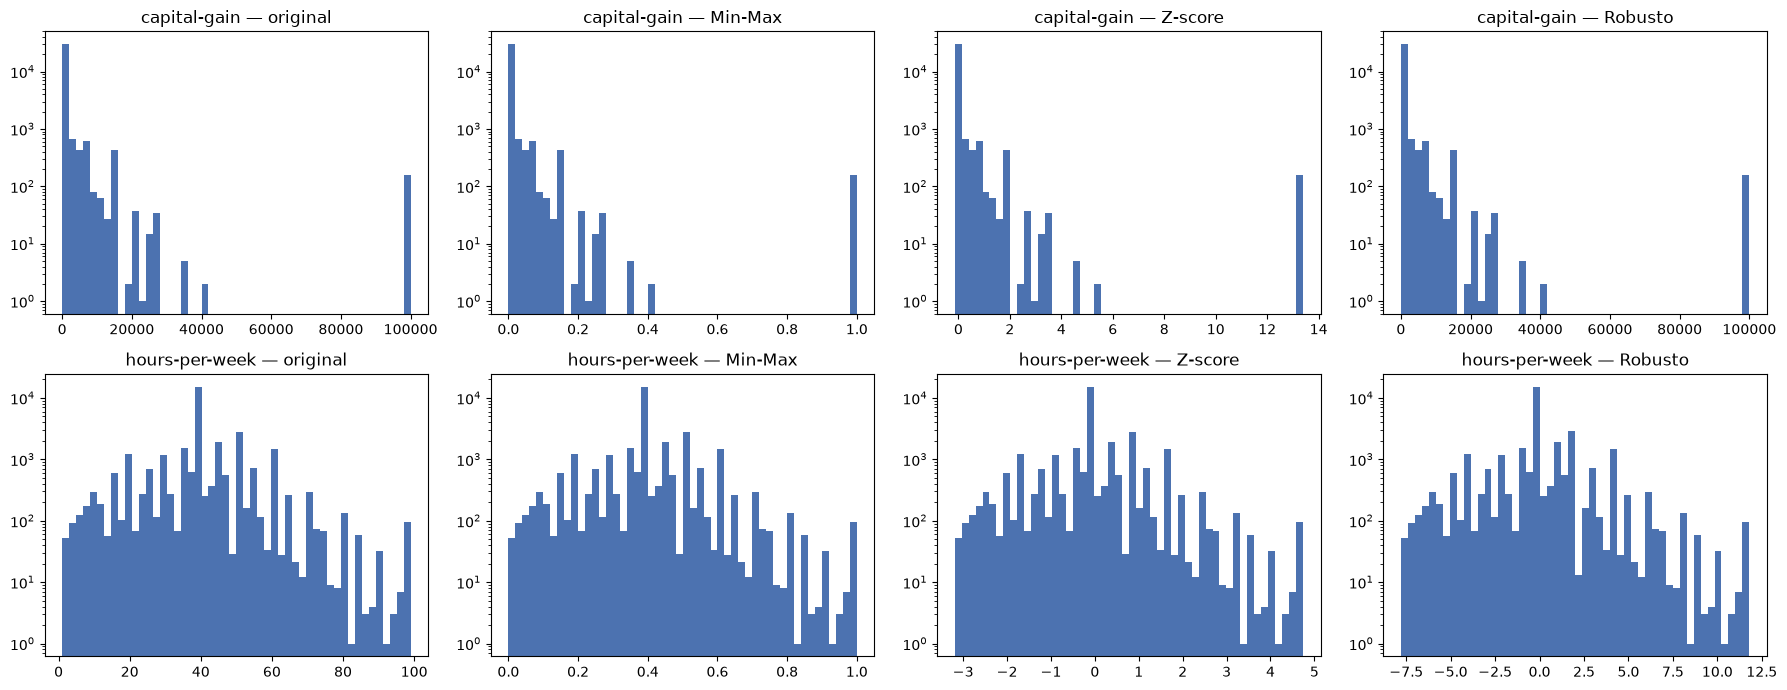

In [15]:
# Comportamento em colunas com muitos extremos: capital-gain e age/hours (mais "bem-comportadas")
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for linha, col in enumerate(['capital-gain', 'hours-per-week']):
    for ax, (nome, dados) in zip(axes[linha], [('original', X), ('Min-Max', X_minmax), ('Z-score', X_z), ('Robusto', X_rob)]):
        ax.hist(dados[col], bins=50, color='#4C72B0')
        ax.set_yscale('log')
        ax.set_title(f'{col} — {nome}')
plt.tight_layout(); plt.show()

In [16]:
# Quantifica o efeito em capital-gain
cg = X['capital-gain']
print(f"% de zeros em capital-gain: {(cg == 0).mean()*100:.1f}%")
print(f"Valores iguais a 99999 (teto): {(cg == 99999).sum()}  |  maior valor abaixo do teto: {cg[cg < 99999].max():,.0f}")
print(f"Min-Max : {(X_minmax['capital-gain'] < 0.05).mean()*100:.1f}% dos valores ficam entre 0 e 0,05")
print(f"Z-score : zeros viram {X_z['capital-gain'][cg == 0].iloc[0]:.3f}; máximo vira {X_z['capital-gain'].max():.2f} desvios")
print(f"Robusto : IQR real = {iqr_real['capital-gain']:.0f} (escala usada = {rob.scale_[3]:.0f}) -> máximo continua {X_rob['capital-gain'].max():,.0f} (nada foi reescalado)")

% de zeros em capital-gain: 91.7%
Valores iguais a 99999 (teto): 159  |  maior valor abaixo do teto: 41,310
Min-Max : 94.9% dos valores ficam entre 0 e 0,05
Z-score : zeros viram -0.146; máximo vira 13.39 desvios
Robusto : IQR real = 0 (escala usada = 1) -> máximo continua 99,999 (nada foi reescalado)


**Leitura da comparação:**
- **Min-Max** coloca tudo em [0, 1], mas depende do mínimo e do máximo. Em `capital-gain`, o máximo é 99.999, então praticamente todos os valores (que são zero ou poucos milhares) ficam **espremidos perto de 0**, e a escala perde resolução. Um único valor extremo define a régua inteira.
- **Z-score** centra em média 0 e desvio 1 (e confere: média ≈ 0 e desvio = 1 em todas as colunas). Em colunas com poucos extremos (`age`, `hours-per-week`) funciona bem. Em `capital-gain`, a média e o desvio **são puxados pelos valores extremos**, então os zeros viram um número negativo pequeno e os valores altos viram z-scores enormes (mais de 10 desvios).
- **Robusto** usa mediana e IQR, que ignoram extremos. Funciona muito bem em `age` e `hours-per-week`, mas em `capital-gain` mostra um caso limite: **mais de 75% dos valores são zero**, então o IQR real é **0**. Não dá para dividir por zero, e o scikit-learn usa escala = 1: **os valores não são escalonados** (o máximo continua 99.999). Em `capital-loss` acontece o mesmo.

## Respostas às perguntas de reflexão
**1. Por que `df.isna().sum()` pode retornar zero em todas as colunas de um dataset que, na verdade, tem dados faltando?**
Porque `isna()` só reconhece como ausente o que o pandas **sabe** que é ausente (`NaN`, `None`, `NaT` e campos vazios na leitura do CSV). Quando quem coletou os dados usou um **marcador próprio** (`?`, `-`, `N/A` escrito de outra forma, `999`, `0`, "desconhecido"), o pandas o lê como um valor qualquer. Foi exatamente o que aconteceu: o Adult tem **4.262 valores ausentes** escondidos atrás de `?`, e o `isna()` retornava 0. Para detectar isso é preciso **olhar os valores únicos** de cada coluna (`value_counts`), conferir categorias suspeitas e consultar a documentação. Depois, converter com `replace('?', np.nan)` ou, ao ler, `na_values='?'`.

**2. Em `capital-gain`, a grande maioria dos valores é zero. Qual técnica é mais afetada? Justifique com os resultados.**
Depende do sentido de "afetada", mas a mais prejudicada é a **robusta**: como mais de 91% dos valores são zero, o **IQR vale 0** e o `RobustScaler` não consegue escalonar a coluna: o resultado é praticamente idêntico ao original (máximo continua em 99.999). A técnica que *deveria* ser a mais resistente a extremos acaba **sem efeito**. O **Min-Max** também é muito afetado: o teto de 99.999 comprime quase todos os valores para perto de 0. O **Z-score** é o menos pior, mas distorcido (média e desvio calculados em cima de extremos; z-scores de mais de 10). A conclusão é que, para variáveis com forte concentração em zero e cauda longa, **nenhuma das três** funciona bem como está, e o caminho é uma **transformação antes** (como `log1p`) ou criar uma variável binária ("teve ganho de capital?"). Vale notar ainda que 99.999 parece ser um **valor-teto** (código de "valor muito alto"), e não um valor real: 159 linhas têm exatamente 99.999, enquanto o maior valor abaixo disso é 41.310.

**3. Faz sentido escalonar todas as colunas numéricas? Pesquise o que `fnlwgt` representa.**
Não. O `fnlwgt` (*final weight*) é o **peso amostral do censo**: o número de pessoas da população que aquela linha representa, calculado pelo Census Bureau para corrigir o desenho da amostra. Ele **não descreve a pessoa**; descreve a **amostragem**. Escalonar `fnlwgt` e usá-lo como atributo preditivo é conceitualmente errado, porque o modelo aprenderia padrões da forma como o censo foi amostrado, não do comportamento das pessoas. O uso correto é como **`sample_weight`** (peso das observações) em cálculos de estatísticas e no treino, ou **descartá-lo**. Também discutível: `education-num` é só uma **codificação ordinal** de `education` (as duas colunas dizem a mesma coisa), então escalonar as duas é redundante. Escalonar faz sentido para variáveis numéricas **com significado quantitativo** (`age`, `hours-per-week`, `capital-*`) quando o algoritmo é sensível à escala (KNN, SVM, regressão regularizada, redes neurais), e **não faz diferença** para modelos baseados em árvore. Por fim, em um projeto de modelagem, os escaladores devem ser ajustados (`fit`) **só nos dados de treino** para evitar vazamento de informação do teste.